In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
#load the data set and convert into dataframe
student_content=pd.read_csv("student_per.csv") #the readed content is converted into data frame

In [33]:
#copy of the orginal data frame and i am going to work on the copy of the data frame
student_content_copy=student_content.copy()
student_content_copy.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [34]:
student_content_copy.shape

(1000, 12)

In [35]:
#information about the data frame
student_content_copy.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    object 
 2   Gender                     952 non-null    object 
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    object 
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(4)
memory usage: 93.9+ KB


In [36]:
#mathematical characteristics before handling the missing values
student_content_copy.describe()

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,960.000000,960.000000,950.000000,967.000000,957.000000,960.000000,976.000000,959.000000
mean,5416.019792,85.510417,17.630526,77.598759,1.520376,80.030208,2.406967,77.248175
std,2653.748319,7.332125,6.272132,10.006640,1.046439,9.493652,1.620267,19.298148
min,1.000000,70.000000,8.000000,60.000000,0.000000,62.000000,-5.000000,50.000000
25%,3113.500000,82.000000,12.000000,70.000000,1.000000,72.000000,1.200000,63.000000
50%,5396.500000,88.000000,18.000000,78.000000,1.000000,80.000000,2.500000,76.000000
75%,7754.750000,91.000000,22.000000,86.000000,2.000000,88.000000,3.700000,89.000000
max,9998.000000,95.000000,30.000000,90.000000,3.000000,92.000000,5.000000,200.000000


In [37]:
#checking for null values for each column
student_content_copy.isnull().sum()


StudentID                    40
Name                         34
Gender                       48
AttendanceRate               40
StudyHoursPerWeek            50
PreviousGrade                33
ExtracurricularActivities    43
ParentalSupport              22
FinalGrade                   40
Study Hours                  24
Attendance (%)               41
Online Classes Taken         25
dtype: int64

In [38]:
total_null_values=student_content_copy.isnull().sum().sum()
print(f"Total null values in the data frame: {total_null_values}")

Total null values in the data frame: 440


In [39]:
# data with null StudentID
student_content_copy[student_content_copy[["StudentID"]].isnull().any(axis=1)]

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
14,NaN,James Williams,Male,70.0,20.0,70.0,2.0,Low,88.0,4.4,73.0,True
16,NaN,Courtney Clark,NaN,95.0,25.0,82.0,2.0,Low,68.0,2.7,65.0,True
37,NaN,Christopher Chapman,Male,95.0,25.0,82.0,0.0,High,85.0,2.3,98.0,True
99,NaN,Natalie Kelley,Male,92.0,22.0,60.0,3.0,Medium,80.0,1.6,80.0,False
127,NaN,Tina Chavez,NaN,70.0,20.0,88.0,0.0,Medium,85.0,1.9,59.0,False
170,NaN,Jasmine Williams,Male,95.0,18.0,85.0,1.0,Medium,62.0,3.7,74.0,False
192,NaN,Jonathan Hodges,Female,92.0,25.0,86.0,1.0,High,80.0,1.4,88.0,False
195,NaN,Shirley Jackson,Male,78.0,20.0,60.0,1.0,Medium,72.0,4.7,98.0,True
214,NaN,Kristi Cross,Male,85.0,18.0,60.0,3.0,Medium,85.0,4.8,69.0,True
221,NaN,Steven Wood,Male,70.0,30.0,85.0,2.0,High,NaN,4.9,80.0,True


In [40]:
#Handling the duplicate values in the data frame
dup_count=student_content_copy.duplicated().sum()
if dup_count==0:
    print("No duplicate values found in the data frame.")
else:
    print(f"Duplicate values found: {dup_count}")
    student_content_copy.drop_duplicates(inplace=True)

No duplicate values found in the data frame.


In [41]:
student_content_copy.isnull().any(axis=0)

StudentID                    True
Name                         True
Gender                       True
AttendanceRate               True
StudyHoursPerWeek            True
PreviousGrade                True
ExtracurricularActivities    True
ParentalSupport              True
FinalGrade                   True
Study Hours                  True
Attendance (%)               True
Online Classes Taken         True
dtype: bool

In [42]:
#removing all the row whose StudentID and Name is null
student_content_copy.dropna(subset=["StudentID",'Name'], inplace=True)

In [43]:
student_content_copy.columns=student_content_copy.columns.str.replace(" ","_")

In [44]:
val=student_content_copy[(student_content_copy["Attendance_(%)"]>100) | (student_content_copy["Study_Hours"]<0)]

In [45]:
student_content_copy.drop(val.index,inplace=True)

In [46]:
student_content_copy.reset_index(drop=True, inplace=True)

<Axes: xlabel='Attendance_(%)'>

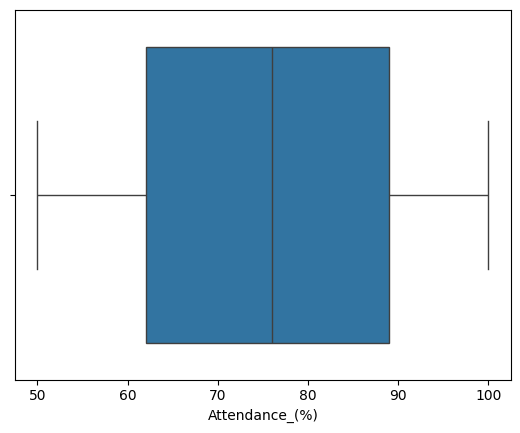

In [47]:
sns.boxplot(x=student_content_copy["Attendance_(%)"])##outlier in Attendance (%)

In [48]:
#Using mean and mode to fill the null values in the data frame
student_content_copy["AttendanceRate"]=student_content_copy["AttendanceRate"].fillna(student_content_copy["AttendanceRate"].mean())
student_content_copy["Gender"]=student_content_copy["Gender"].fillna(student_content_copy["Gender"].mode()[0])
student_content_copy["ParentalSupport"]=student_content_copy["ParentalSupport"].fillna(student_content_copy["ParentalSupport"].mode()[0])
student_content_copy["StudyHoursPerWeek"]=student_content_copy["StudyHoursPerWeek"].fillna(student_content_copy["StudyHoursPerWeek"].mean())
student_content_copy["PreviousGrade"]=student_content_copy["PreviousGrade"].fillna(student_content_copy["PreviousGrade"].mean())
student_content_copy["ExtracurricularActivities"]=student_content_copy["ExtracurricularActivities"].fillna(student_content_copy["ExtracurricularActivities"].mean())
student_content_copy["FinalGrade"]=student_content_copy["FinalGrade"].fillna(student_content_copy["FinalGrade"].mean())
student_content_copy["Study_Hours"]=student_content_copy["Study_Hours"].fillna(student_content_copy["Study_Hours"].mean())
student_content_copy["Attendance_(%)"]=student_content_copy["Attendance_(%)"].fillna(student_content_copy["Attendance_(%)"].median())
student_content_copy["Online_Classes_Taken"]=student_content_copy["Online_Classes_Taken"].fillna(student_content_copy["Online_Classes_Taken"].mode()[0])

C:\Users\deepa\AppData\Local\Temp\ipykernel_38432\3528080651.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  student_content_copy["Online_Classes_Taken"]=student_content_copy["Online_Classes_Taken"].fillna(student_content_copy["Online_Classes_Taken"].mode()[0])


In [49]:
student_content_copy.shape

(916, 12)

In [50]:
len(student_content_copy["StudentID"])

916

In [51]:
len(student_content_copy["StudentID"].unique())

875

In [52]:
student_content_copy.drop_duplicates(subset=["StudentID"], inplace=True)

In [53]:
student_content_copy.shape

(875, 12)

In [54]:
student_content_copy.corr(numeric_only=True)

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study_Hours,Attendance_(%),Online_Classes_Taken
StudentID,1.000000,0.066941,-0.020683,-0.020639,-0.034224,0.080179,0.024455,-0.021535,0.019768
AttendanceRate,0.066941,1.000000,0.024919,0.041095,-0.013297,-0.012291,-0.038532,0.032828,0.016760
StudyHoursPerWeek,-0.020683,0.024919,1.000000,0.006635,0.051984,0.011641,-0.020116,0.047605,-0.026166
PreviousGrade,-0.020639,0.041095,0.006635,1.000000,0.059481,-0.000202,-0.056219,0.081520,-0.013891
ExtracurricularActivities,-0.034224,-0.013297,0.051984,0.059481,1.000000,-0.023608,-0.057671,-0.002700,0.007616
FinalGrade,0.080179,-0.012291,0.011641,-0.000202,-0.023608,1.000000,0.054555,0.023105,0.009964
Study_Hours,0.024455,-0.038532,-0.020116,-0.056219,-0.057671,0.054555,1.000000,-0.001100,-0.039357
Attendance_(%),-0.021535,0.032828,0.047605,0.081520,-0.002700,0.023105,-0.001100,1.000000,0.042415
Online_Classes_Taken,0.019768,0.016760,-0.026166,-0.013891,0.007616,0.009964,-0.039357,0.042415,1.000000


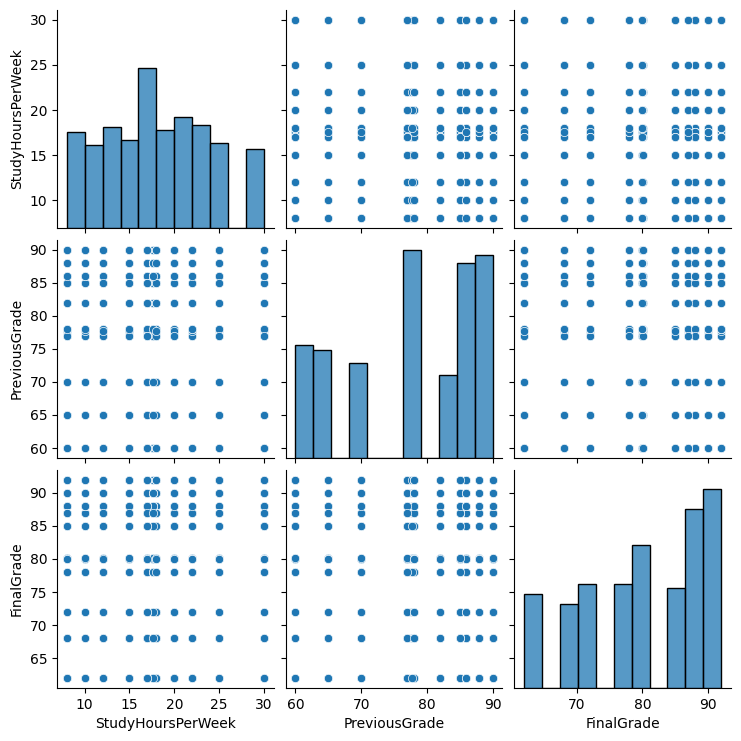

In [55]:
sns.pairplot(student_content_copy[["StudyHoursPerWeek","PreviousGrade","FinalGrade"]])

In [56]:
student_content_copy.reset_index(drop=True, inplace=True)
student_content_copy

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study_Hours,Attendance_(%),Online_Classes_Taken
0,1.0,John,Male,85.000000,15.000000,78.0,1.0,High,80.000000,4.8,59.0,False
1,2.0,Sarah,Female,90.000000,20.000000,85.0,2.0,Medium,87.000000,2.2,70.0,True
2,3.0,Alex,Male,78.000000,10.000000,65.0,0.0,Low,68.000000,4.6,92.0,False
3,4.0,Michael,Male,92.000000,25.000000,90.0,3.0,High,92.000000,2.9,96.0,False
4,5.0,Emma,Female,85.511945,18.000000,82.0,2.0,Medium,85.000000,4.1,97.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
870,3592.0,Monica Johnson,Female,90.000000,25.000000,60.0,1.0,Low,87.000000,1.7,79.0,False
871,2787.0,Shannon Porter,Male,78.000000,20.000000,60.0,0.0,High,62.000000,1.6,70.0,False
872,4497.0,Amy Stout,Female,91.000000,17.572414,86.0,0.0,High,90.000000,3.9,80.0,True
873,7636.0,Joseph Sherman,Male,88.000000,17.000000,60.0,2.0,High,85.000000,0.9,53.0,True


<Axes: xlabel='Attendance_(%)'>

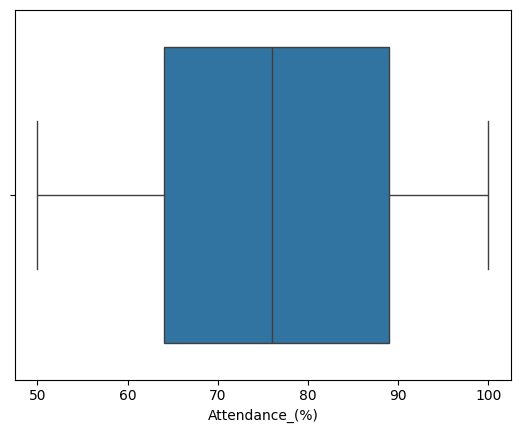

In [57]:
sns.boxplot(x=student_content_copy["Attendance_(%)"])##outlier in Attendance (%)

<Axes: >

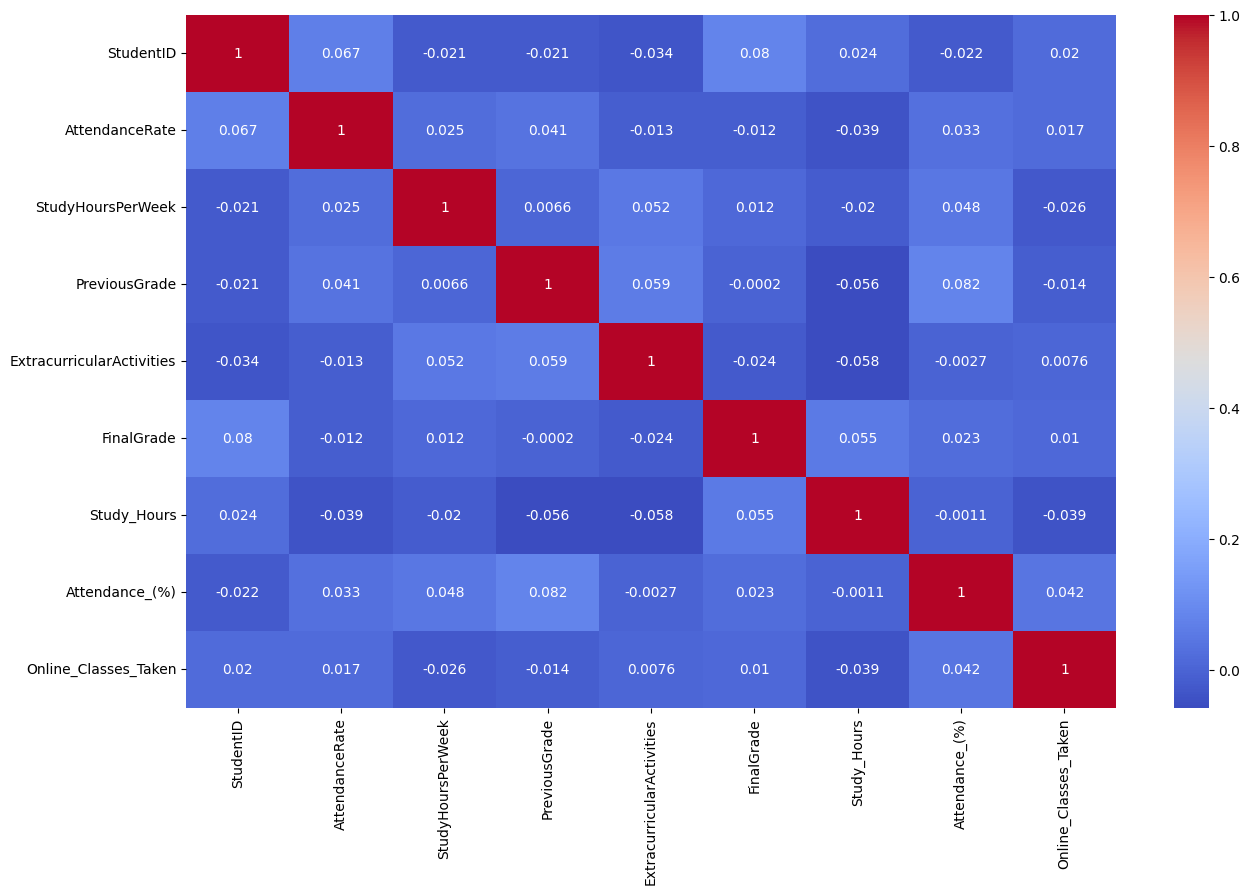

In [58]:
fig=plt.figure(figsize=(15,9))
sns.heatmap(student_content_copy.corr(numeric_only=True), annot=True, cmap="coolwarm")

In [59]:
#student_content_copy.to_csv("modified data.csv")

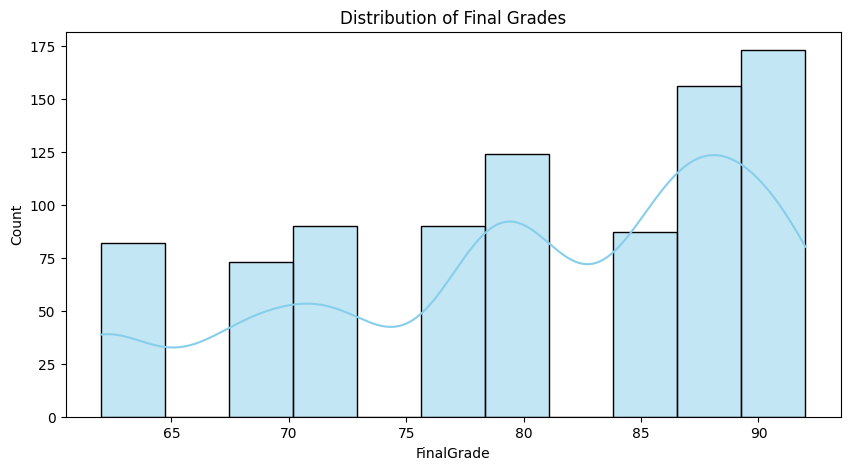

In [60]:
plt.figure(figsize=(10, 5))
sns.histplot(student_content_copy['FinalGrade'], kde=True, color='skyblue')
plt.title('Distribution of Final Grades')
plt.show()